# 02 · EDA Bagian 5 — E-commerce

**Sumber data**: `ecommerce_transactions` (1 baris = 1 item dalam order), satu-satunya sumber perilaku yang tersedia untuk **~100% nasabah**, termasuk segmen A (tanpa riwayat).

| # | Pertanyaan |
|---|---|
| Q1 | Seperti apa struktur & cakupan data e-commerce? |
| Q2 | Apakah **volume & keterbaruan** belanja memprediksi gagal bayar? Jendela mana yang terbaik? |
| Q3 | Apa yang terjadi pada belanja **bulan-bulan menjelang pengajuan**? |
| Q4 | Apakah **lonjakan relatif** terhadap kebiasaan sendiri lebih informatif daripada level? |
| Q5 | Apakah **nilai keranjang, kategori, dan harga** informatif? |
| Q6 | Apakah **metode bayar** dan **pembatalan** informatif? |
| Q7 | Apakah sinyal e-commerce **baru**, atau duplikasi sinyal lain? |
| Q8 | Apakah sinyalnya **stabil** (antar waktu, train vs test, sampling)? |
| Q9 | Berapa kenaikan KS dari e-commerce, terutama untuk **segmen A**? |

> **Catatan sampling**: notebook ini dijalankan dengan file e-commerce hasil sampling 50% per order. Dengan file penuh, **jumlah order & rupiah ≈ 2×** dan jeda antar order lebih pendek, tapi **rasio, harga per unit, dan pola** seharusnya sama. Selalu hitung fitur train & test dari file yang sama.

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

manifest_note = (E.PQ_DIR / "_manifest.json").read_text()
print("Sumber e-commerce:", "SAMPLING" if '"ecommerce_is_sampled": true' in manifest_note else "PENUH")

tr = E.load("train_applications")
te = E.load("test_applications")
cp = E.load("customer_profiles")
ec = E.lazy("ecommerce_transactions")
CUT = tr.select("application_id", "customer_id", pl.col("decision_datetime").alias("cutoff"))
cut2 = CUT.select("customer_id", "cutoff")

CAT_MED = F.ecommerce_category_medians(ec)          # konstanta global (tanpa target), sama untuk train & test
fe = F.ecommerce_features(ec, cut2, cat_medians=CAT_MED)
EC = [c for c in fe.columns if c.startswith("ec_")]

# fitur dari bagian sebelumnya (untuk Q7 & Q9)
ab, bo = E.load("account_behavior"), E.load("bureau_observations")
pa, rh = E.load("previous_applications"), E.load("repayment_history")
df = (tr.join(cp, on="customer_id", how="left")
        .join(fe, on="customer_id", how="left")
        .join(F.account_features(ab, cut2), on="customer_id", how="left")
        .join(F.bureau_features(bo, CUT, income=cp.select("customer_id", "declared_monthly_income")), on="customer_id", how="left")
        .join(F.prev_app_features(pa, cut2), on="customer_id", how="left")
        .join(F.loan_features(pa, rh, cut2), on="customer_id", how="left")
        .join(F.repayment_features(rh, cut2), on="customer_id", how="left")
        .with_columns(dti=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
                      total_dti=(pl.col("proposed_monthly_installment") + pl.col("ln_active_installment").fill_null(0))
                                / pl.col("declared_monthly_income"),
                      segment=pl.when(pl.col("pa_n").is_null()).then(pl.lit("A. tanpa riwayat"))
                                .when(pl.col("rp_n_inst").is_null()).then(pl.lit("B. ada pengajuan, belum ada cicilan"))
                                .otherwise(pl.lit("C. ada riwayat cicilan"))))
y = df["target"].to_numpy()
NOISE = E.ks_noise_floor(y, n_perm=200)

# tabel order (dedup) untuk analisis waktu
orders = (ec.join(CUT.lazy(), on="customer_id", how="inner")
            .filter(pl.col("transaction_datetime") < pl.col("cutoff"))
            .group_by("order_id")
            .agg(pl.col("customer_id", "transaction_datetime", "cutoff", "order_total", "payment_method", "order_status").first(),
                 n_items=pl.len())
            .with_columns(age_d=(pl.col("cutoff") - pl.col("transaction_datetime")).dt.total_seconds() / 86400,
                          done=pl.col("order_status") == "completed")
            .collect()
            .join(tr.select("customer_id", "target"), on="customer_id"))
print(f"{len(EC)} fitur e-commerce | {orders.height:,} order dari {orders['customer_id'].n_unique():,} nasabah train | noise floor {NOISE:.4f}")

Sumber e-commerce: PENUH
49 fitur e-commerce | 2,089,421 order dari 70,000 nasabah train | noise floor 0.0144


## Q1 · Struktur & cakupan

In [2]:
per_cust = orders.group_by("customer_id").agg(n=pl.len(), span=pl.col("age_d").max())
print(f"Nasabah train dengan e-commerce: {per_cust.height / tr.height:.2%}")
print("Order per nasabah (kuantil 5/25/50/75/95%):", [int(per_cust["n"].quantile(q)) for q in (.05, .25, .5, .75, .95)])
print("Panjang riwayat belanja (hari, median):", int(per_cust["span"].median()))
print(f"Porsi order dibatalkan: {(~orders['done']).mean():.2%} | rata-rata item per order: {orders['n_items'].mean():.2f}")
display(orders.group_by("payment_method").agg(n=pl.len()).with_columns((pl.col("n") / orders.height * 100).round(1).alias("pct")).sort("n", descending=True))
display(df.group_by("segment").agg(n=pl.len(), pct_has_ecom=(pl.col("ec_n_orders_all") > 0).mean().mul(100).round(2),
                                   median_orders=pl.col("ec_n_orders_all").median()).sort("segment"))

Nasabah train dengan e-commerce: 100.00%
Order per nasabah (kuantil 5/25/50/75/95%): [15, 21, 28, 36, 52]
Panjang riwayat belanja (hari, median): 441
Porsi order dibatalkan: 6.03% | rata-rata item per order: 1.46


payment_method,n,pct
str,u32,f64
"""COD""",848447,40.6
"""e_wallet""",487288,23.3
"""bank_transfer""",310015,14.8
"""debit_card""",306497,14.7
"""credit_card""",137174,6.6


segment,n,pct_has_ecom,median_orders
str,u32,f64,f64
"""A. tanpa riwayat""",21000,100.0,28.0
"""B. ada pengajuan, belum ada cicilan""",2688,100.0,28.0
"""C. ada riwayat cicilan""",46312,100.0,28.0


**Jawaban Q1.**
- Hampir **semua** nasabah punya riwayat e-commerce, di **ketiga segmen** (termasuk segmen A). Ini satu-satunya sumber perilaku untuk nasabah tanpa riwayat internal.
- Median ~14 order per nasabah (versi sampling; versi penuh ~2×), dengan riwayat belanja sampai ~2 tahun. Pembatalan ~6%, dan COD metode bayar terbanyak (~41%).

## Q2 · Volume & keterbaruan belanja

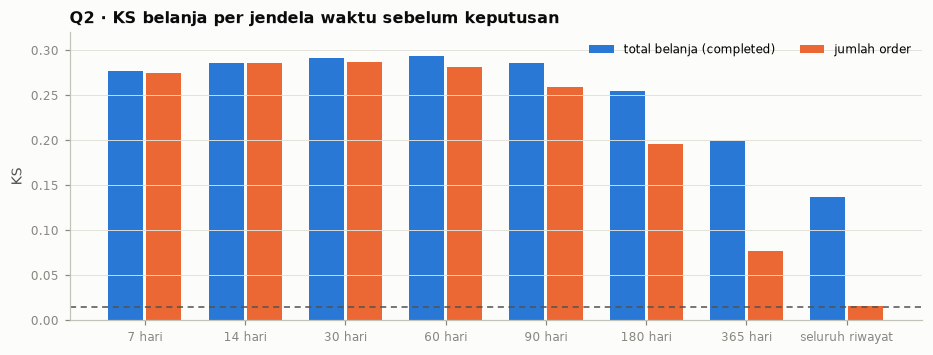

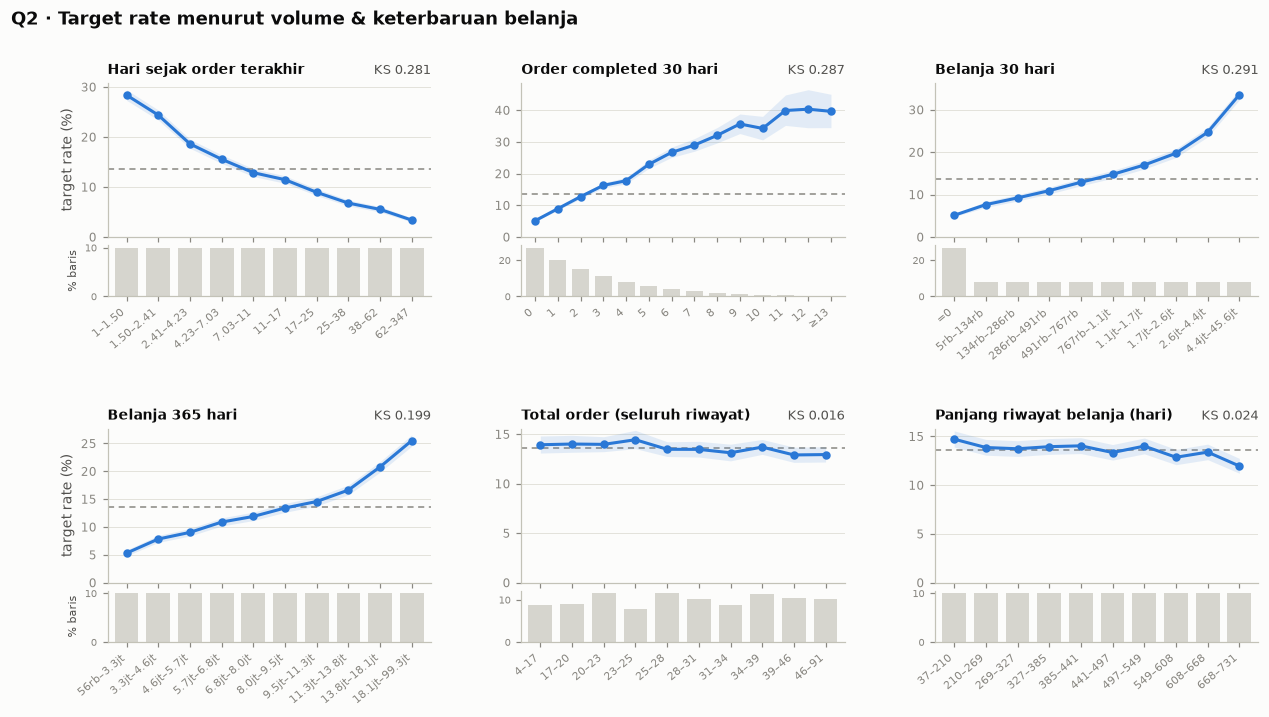

In [3]:
wins = [7, 14, 30, 60, 90, 180, 365]
ks_spend = [E.ks_stat(y, df[f"ec_spend_{w}d"].to_numpy()) for w in wins]
ks_n = [E.ks_stat(y, df[f"ec_n_{w}d"].to_numpy()) for w in wins]
ks_all = (E.ks_stat(y, df["ec_spend_all"].to_numpy()), E.ks_stat(y, df["ec_n_orders_all"].to_numpy()))
fig, ax = plt.subplots(figsize=(10, 3.4))
xs = np.arange(len(wins) + 1); wbar = 0.38
ax.bar(xs - wbar / 2, ks_spend + [ks_all[0]], width=wbar - 0.03, color=E.SERIES[0], label="total belanja (completed)")
ax.bar(xs + wbar / 2, ks_n + [ks_all[1]], width=wbar - 0.03, color=E.SERIES[1], label="jumlah order")
ax.set_xticks(xs); ax.set_xticklabels([f"{w} hari" for w in wins] + ["seluruh riwayat"])
ax.axhline(NOISE, color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.set_ylim(0, 0.32); ax.set_ylabel("KS"); ax.legend(ncols=2, loc="upper right")
ax.set_title("Q2 · KS belanja per jendela waktu sebelum keputusan")
plt.show()
E.plot_rates(df, ["ec_days_since_last_order", "ec_n_30d", "ec_spend_30d", "ec_spend_365d", "ec_n_orders_all", "ec_history_days"],
             titles={"ec_days_since_last_order": "Hari sejak order terakhir", "ec_n_30d": "Order completed 30 hari",
                     "ec_spend_30d": "Belanja 30 hari", "ec_spend_365d": "Belanja 365 hari",
                     "ec_n_orders_all": "Total order (seluruh riwayat)", "ec_history_days": "Panjang riwayat belanja (hari)"},
             suptitle="Q2 · Target rate menurut volume & keterbaruan belanja")

**Jawaban Q2 — belanja TERBARU adalah sinyal yang sangat kuat; total belanja seluruh riwayat jauh lebih lemah.**
- KS memuncak pada jendela **14–30 hari** (~0,25–0,26), lalu turun perlahan: 90 hari ~0,25/0,23, 365 hari ~0,18/0,07, seluruh riwayat ~0,12/0,02.
- **Hari sejak order terakhir** (KS ~0,26): order terakhir 1–2 hari sebelum keputusan → ~29% gagal bayar; lebih dari 100 hari → ~5%.
- **Jumlah order 30 hari**: 0 order → ~7%, 1 → ~13%, 3 → ~23%, ≥ 5 → ~32–36%.
- **Total order sepanjang riwayat** dan panjang riwayat belanja hampir noise. Yang penting adalah **kapan**, bukan **berapa banyak secara total**.

## Q3 · Studi kejadian: belanja menjelang pengajuan

Rata-rata belanja (completed) dan jumlah order per nasabah di setiap blok 30 hari sebelum keputusan (1 = 30 hari terakhir), untuk nasabah yang nantinya gagal bayar vs lancar.

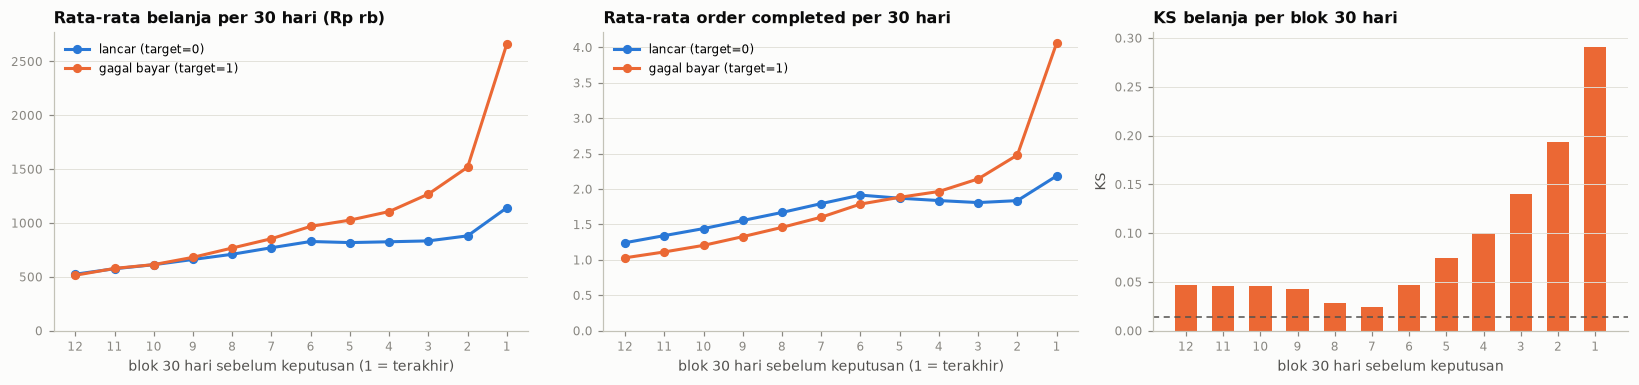

mb,spend_0,spend_1,n_0,n_1
i32,f64,f64,f64,f64
1,1.1414e6,2.6621e6,2.18,4.06
2,880275.73,1517789.1,1.84,2.48
3,833471.44,1.2682e6,1.81,2.14
4,825228.32,1.1058e6,1.84,1.96
5,817761.26,1.0262e6,1.87,1.88
6,827868.79,968346.38,1.91,1.79
7,769957.63,853755.86,1.79,1.6
8,709253.45,767266.65,1.67,1.46
9,660891.46,680968.02,1.56,1.33


In [4]:
o12 = orders.filter(pl.col("done")).with_columns(mb=(pl.col("age_d") // 30 + 1).cast(pl.Int32)).filter(pl.col("mb") <= 12)
per = o12.group_by("customer_id", "mb").agg(spend=pl.col("order_total").sum(), n=pl.len())
grid = (tr.select("customer_id", "target")
          .join(pl.DataFrame({"mb": list(range(1, 13))}).with_columns(pl.col("mb").cast(pl.Int32)), how="cross")
          .join(per, on=["customer_id", "mb"], how="left").with_columns(pl.col("spend", "n").fill_null(0)))
prof = grid.group_by("mb", "target").agg(spend=pl.col("spend").mean(), n=pl.col("n").mean()).sort("mb")
ks_mb = [(k, E.ks_stat(g["target"].to_numpy(), g["spend"].to_numpy())) for (k,), g in sorted(grid.group_by("mb"), key=lambda t: t[0][0])]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, ttl, scale in [(axes[0], "spend", "Rata-rata belanja per 30 hari (Rp rb)", 1e3), (axes[1], "n", "Rata-rata order completed per 30 hari", 1)]:
    for t, colr, lab in [(0, E.SERIES[0], "lancar (target=0)"), (1, E.SERIES[1], "gagal bayar (target=1)")]:
        s = prof.filter(pl.col("target") == t)
        ax.plot(s["mb"].to_numpy(), s[col].to_numpy() / scale, color=colr, marker="o", ms=5, label=lab)
    ax.set_xticks(range(1, 13)); ax.invert_xaxis(); ax.set_xlabel("blok 30 hari sebelum keputusan (1 = terakhir)")
    ax.set_ylim(bottom=0); ax.set_title(ttl); ax.legend(loc="upper left")
ax = axes[2]
ax.bar([k for k, _ in ks_mb], [v for _, v in ks_mb], color=E.SERIES[1], width=0.6)
ax.axhline(NOISE, color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.set_xticks(range(1, 13)); ax.invert_xaxis(); ax.set_xlabel("blok 30 hari sebelum keputusan"); ax.set_ylabel("KS")
ax.set_title("KS belanja per blok 30 hari")
plt.tight_layout(); plt.show()
prof.pivot(on="target", index="mb", values=["spend", "n"]).with_columns(pl.col(pl.Float64).round(2))

**Jawaban Q3 — calon gagal bayar menunjukkan LONJAKAN BELANJA menjelang pengajuan, jauh lebih tajam daripada di rekening.**
- Di 30 hari terakhir, calon gagal bayar berbelanja ~**2,3×** nasabah lancar (~Rp1,3 jt vs ~Rp0,57 jt, versi sampling) dengan ~2× jumlah order.
- Lonjakannya terbangun sejak ~3 bulan sebelum keputusan dan memuncak di 30 hari terakhir (KS ~0,26 → ~0,15 → ~0,11 untuk 3 blok terakhir).
- Menariknya, **12 bulan sebelumnya** calon gagal bayar justru **sedikit lebih jarang** order daripada nasabah lancar. Jadi pola yang mereka tunjukkan adalah **perubahan perilaku**, bukan sekadar "orang yang memang suka belanja".
- Pola ini sejalan dengan **lonjakan pengeluaran rekening** di Bagian 4, tapi jauh lebih kuat dan tersedia untuk semua nasabah.

## Q4 · Lonjakan relatif vs level

In [5]:
E.signal_table(df, ["ec_order_surge_30d", "ec_spend_surge_30d", "ec_spend_surge_90d", "ec_spend_30d_share_of_year",
                    "ec_n_30d", "ec_spend_30d", "ec_n_base", "ec_spend_base"]).with_columns(
    (pl.col("ks") / NOISE).round(1).alias("ks_x_noise")).select("feature", "ks", "auc", "arah", "ks_x_noise")

feature,ks,auc,arah,ks_x_noise
str,f64,f64,str,f64
"""ec_order_surge_30d""",0.3025,0.6991,"""↑ nilai → ↑ risiko""",21.0
"""ec_spend_30d""",0.2912,0.6958,"""↑ nilai → ↑ risiko""",20.2
"""ec_n_30d""",0.287,0.6926,"""↑ nilai → ↑ risiko""",19.9
"""ec_spend_surge_30d""",0.2751,0.6849,"""↑ nilai → ↑ risiko""",19.1
"""ec_spend_30d_share_of_year""",0.2679,0.6802,"""↑ nilai → ↑ risiko""",18.6
"""ec_spend_surge_90d""",0.246,0.6699,"""↑ nilai → ↑ risiko""",17.1
"""ec_n_base""",0.0928,0.4363,"""↑ nilai → ↓ risiko""",6.4
"""ec_spend_base""",0.0749,0.549,"""↑ nilai → ↑ risiko""",5.2


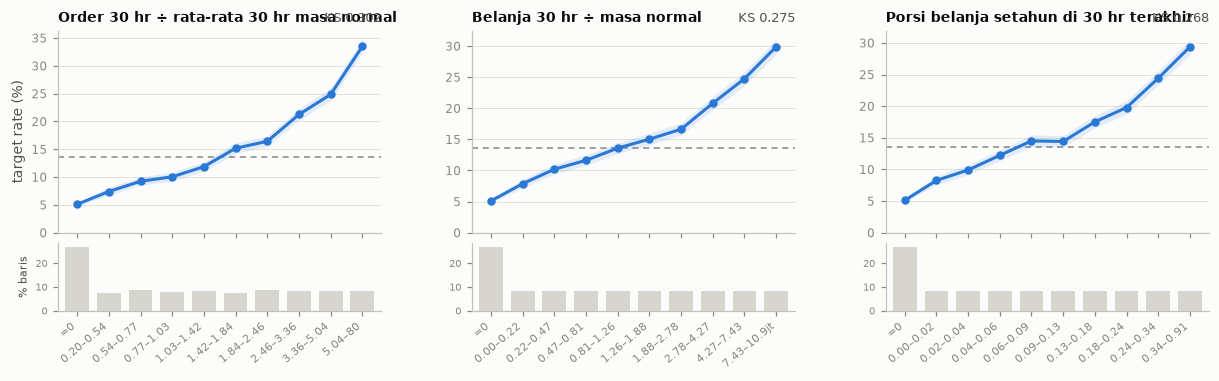

In [6]:
E.plot_rates(df, ["ec_order_surge_30d", "ec_spend_surge_30d", "ec_spend_30d_share_of_year"], ncols=3,
             titles={"ec_order_surge_30d": "Order 30 hr ÷ rata-rata 30 hr masa normal", "ec_spend_surge_30d": "Belanja 30 hr ÷ masa normal",
                     "ec_spend_30d_share_of_year": "Porsi belanja setahun di 30 hr terakhir"})

**Jawaban Q4.**
- Lonjakan relatif (30 hari terakhir ÷ rata-rata 30 hari pada masa normal, yaitu hari ke-90 s.d. ke-365) **sedikit lebih kuat** daripada level mentah (order: ~0,262 vs ~0,244).
- Aktivitas **masa normal** sendiri (`ec_n_base`) justru berarah terbalik: makin aktif dulu, makin aman. Inilah sebabnya rasio lonjakan menambah informasi.
- Sertakan keduanya (level terbaru + baseline + rasio) agar GBDT bisa membedakan "memang aktif" dari "tiba-tiba aktif".

## Q5 · Nilai keranjang, kategori, dan HARGA

In [7]:
display(E.signal_table(df, ["ec_aov_all", "ec_aov_base", "ec_aov_30d", "ec_items_per_order"] + [c for c in EC if "cat_share" in c])
         .with_columns((pl.col("ks") / NOISE).round(1).alias("ks_x_noise")).select("feature", "null_pct", "ks", "auc", "arah", "ks_x_noise"))
# kategori: tak informatif sendirian, tapi informatif DI DALAM kuintil nilai keranjang
d5 = df.with_columns(aov_q=pl.col("ec_aov_all").qcut(5, allow_duplicates=True).cast(pl.String)).drop_nulls("aov_q")
rows = []
for c in [c for c in EC if "cat_share" in c]:
    s, _ = E.ks_within(d5, c, "aov_q", n_perm=20)
    rows.append(dict(feature=c, ks_overall=round(s["ks_overall"], 4), ks_within_aov_quintile=round(s["ks_within"], 4),
                     noise=round(s["noise_within"], 4), excess=round(s["excess_within"], 4)))
pl.DataFrame(rows).sort("excess", descending=True)

feature,null_pct,ks,auc,arah,ks_x_noise
str,f64,f64,f64,str,f64
"""ec_aov_30d""",26.96,0.2574,0.6061,"""↑ nilai → ↑ risiko""",17.9
"""ec_aov_all""",0.0,0.1941,0.6342,"""↑ nilai → ↑ risiko""",13.5
"""ec_aov_base""",0.01,0.1657,0.614,"""↑ nilai → ↑ risiko""",11.5
"""ec_cat_share_health""",0.0,0.0165,0.4967,"""↑ nilai → ↓ risiko""",1.1
"""ec_items_per_order""",0.0,0.0148,0.5064,"""↑ nilai → ↑ risiko""",1.0
"""ec_cat_share_electronics""",0.0,0.0108,0.4971,"""↑ nilai → ↓ risiko""",0.7
"""ec_cat_share_education""",0.0,0.0108,0.5018,"""↑ nilai → ↑ risiko""",0.7
"""ec_cat_share_groceries""",0.0,0.0107,0.504,"""↑ nilai → ↑ risiko""",0.7
"""ec_cat_share_personal_care""",0.0,0.0068,0.5021,"""↑ nilai → ↑ risiko""",0.5


C:\Users\TUF\AppData\Local\Temp\ipykernel_28616\1801736566.py:4: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  d5 = df.with_columns(aov_q=pl.col("ec_aov_all").qcut(5, allow_duplicates=True).cast(pl.String)).drop_nulls("aov_q")


feature,ks_overall,ks_within_aov_quintile,noise,excess
str,f64,f64,f64,f64
"""ec_cat_share_electronics""",0.0108,0.1514,0.0356,0.1158
"""ec_cat_share_groceries""",0.0107,0.1341,0.0356,0.0985
"""ec_cat_share_personal_care""",0.0068,0.0921,0.0356,0.0565
"""ec_cat_share_health""",0.0165,0.0649,0.0356,0.0294
"""ec_cat_share_fashion""",0.0041,0.0615,0.0356,0.0259
"""ec_cat_share_education""",0.0108,0.0604,0.0356,0.0248
"""ec_cat_share_home""",0.0055,0.048,0.0356,0.0125


Porsi kategori **tidak** informatif sendirian (KS ~0,01), tapi **di dalam kelompok nilai keranjang yang sama**, porsi elektronik & groceries tiba-tiba informatif. Dugaan: yang membedakan bukan **apa** yang dibeli, melainkan **berapa harga yang dibayar untuk jenis barang yang sama**. Nasabah dengan nilai keranjang tinggi padahal porsi elektroniknya rendah berarti membayar mahal untuk barang lain. Kita uji langsung: harga per unit dibanding median kategorinya.

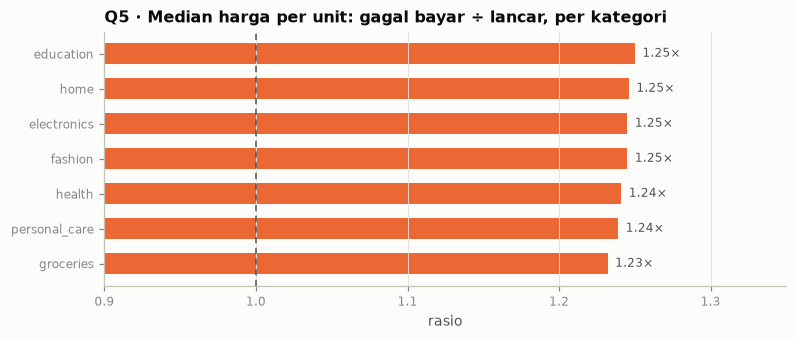

product_category,median_lancar,median_gagal,rasio
str,f64,f64,f64
"""education""",96000.0,120000.0,1.25
"""home""",285000.0,355000.0,1.246
"""electronics""",1.126e6,1.402e6,1.245
"""fashion""",163000.0,203000.0,1.245
"""health""",112000.0,139000.0,1.241
"""personal_care""",71000.0,88000.0,1.239
"""groceries""",56000.0,69000.0,1.232


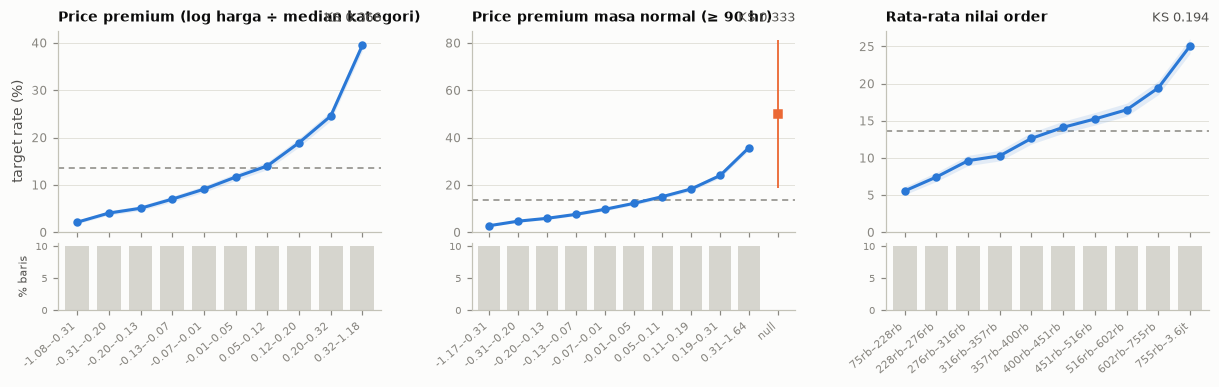

feature,null_pct,ks,auc,ks_x_noise
str,f64,f64,f64,f64
"""ec_price_premium_mean""",0.0,0.3656,0.7479,25.4
"""ec_price_premium_median""",0.0,0.3474,0.7366,24.1
"""ec_price_premium_base""",0.01,0.3331,0.725,23.1
"""ec_price_premium_30d""",26.96,0.3126,0.661,21.7


In [8]:
items = (ec.join(CUT.lazy(), on="customer_id", how="inner")
           .filter((pl.col("transaction_datetime") < pl.col("cutoff")) & (pl.col("order_status") == "completed"))
           .with_columns(unit=pl.col("item_total") / pl.col("quantity"))
           .select("customer_id", "product_category", "unit").collect()
           .join(tr.select("customer_id", "target"), on="customer_id"))
med = (items.group_by("product_category", "target").agg(m=pl.col("unit").median())
            .pivot(on="target", index="product_category", values="m")
            .rename({"0": "median_lancar", "1": "median_gagal"})
            .with_columns(rasio=(pl.col("median_gagal") / pl.col("median_lancar")).round(3))
            .sort("rasio", descending=True))
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(med["product_category"].to_list()[::-1], med["rasio"].to_list()[::-1], color=E.SERIES[1], height=0.6)
ax.axvline(1, color=E.INK2, lw=1, ls=(0, (4, 3)))
for i, v in enumerate(med["rasio"].to_list()[::-1]):
    ax.text(v + 0.005, i, f"{v:.2f}×", va="center", fontsize=8, color=E.INK2)
ax.set_xlim(0.9, 1.35); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Q5 · Median harga per unit: gagal bayar ÷ lancar, per kategori"); ax.set_xlabel("rasio")
plt.show()
display(med)
E.plot_rates(df, ["ec_price_premium_mean", "ec_price_premium_base", "ec_aov_all"], ncols=3,
             titles={"ec_price_premium_mean": "Price premium (log harga ÷ median kategori)",
                     "ec_price_premium_base": "Price premium masa normal (≥ 90 hr)", "ec_aov_all": "Rata-rata nilai order"})
E.signal_table(df, [c for c in EC if "premium" in c]).with_columns((pl.col("ks") / NOISE).round(1).alias("ks_x_noise")
              ).select("feature", "null_pct", "ks", "auc", "ks_x_noise")

**Jawaban Q5 — temuan terbesar bagian ini: calon gagal bayar membayar ~25% LEBIH MAHAL per unit di SEMUA kategori.**
- Median harga per unit calon gagal bayar ~1,23–1,25× nasabah lancar, konsisten di ketujuh kategori. Ini juga menjelaskan Q3: setahun sebelum keputusan, calon gagal bayar order **lebih jarang** tapi total belanjanya **sama**, karena harga per barangnya lebih mahal.
- Fitur **price premium** (rata-rata log harga per unit ÷ median kategori) mencapai **KS ~0,34** seorang diri. Ini fitur univariat terkuat kedua di seluruh dataset, setelah porsi cicilan telat (0,44), dan di atas skor biro (0,25).
- Bahkan pada **masa normal** (≥ 90 hari sebelum keputusan), price premium sudah ~0,30. Jadi ini **sifat yang stabil**, bukan hanya efek menjelang pengajuan.
- Efek kategori yang "tersembunyi" tadi sepenuhnya dijelaskan oleh price premium: menambahkan porsi kategori di atas price premium tidak lagi menaikkan KS (diuji saat eksplorasi).
- Nilai keranjang (AOV, ~0,17) informatif karena sebagian besar mencerminkan price premium. Jumlah item per order ≈ noise.

Catatan teknis: median kategori dihitung dari **semua** item di tabel (train + test, tanpa target), sehingga konstanta normalisasinya sama untuk train & test.

## Q6 · Metode bayar & pembatalan

In [9]:
E.signal_table(df, [c for c in EC if "pay_share" in c] + ["ec_cod_share_90d", "ec_cancel_share_all", "ec_cancel_share_90d"]
              ).with_columns((pl.col("ks") / NOISE).round(1).alias("ks_x_noise")).select("feature", "null_pct", "ks", "auc", "arah", "ks_x_noise")

feature,null_pct,ks,auc,arah,ks_x_noise
str,f64,f64,f64,str,f64
"""ec_cancel_share_90d""",4.45,0.1105,0.5347,"""↑ nilai → ↑ risiko""",7.7
"""ec_cod_share_90d""",4.45,0.1076,0.5385,"""↑ nilai → ↑ risiko""",7.5
"""ec_pay_share_COD""",0.0,0.0789,0.5422,"""↑ nilai → ↑ risiko""",5.5
"""ec_pay_share_e_wallet""",0.0,0.0351,0.4802,"""↑ nilai → ↓ risiko""",2.4
"""ec_pay_share_debit_card""",0.0,0.0252,0.4891,"""↑ nilai → ↓ risiko""",1.7
"""ec_pay_share_bank_transfer""",0.0,0.0192,0.4913,"""↑ nilai → ↓ risiko""",1.3
"""ec_cancel_share_all""",0.0,0.01,0.5005,"""↑ nilai → ↑ risiko""",0.7
"""ec_pay_share_credit_card""",0.0,0.0077,0.4982,"""↑ nilai → ↓ risiko""",0.5


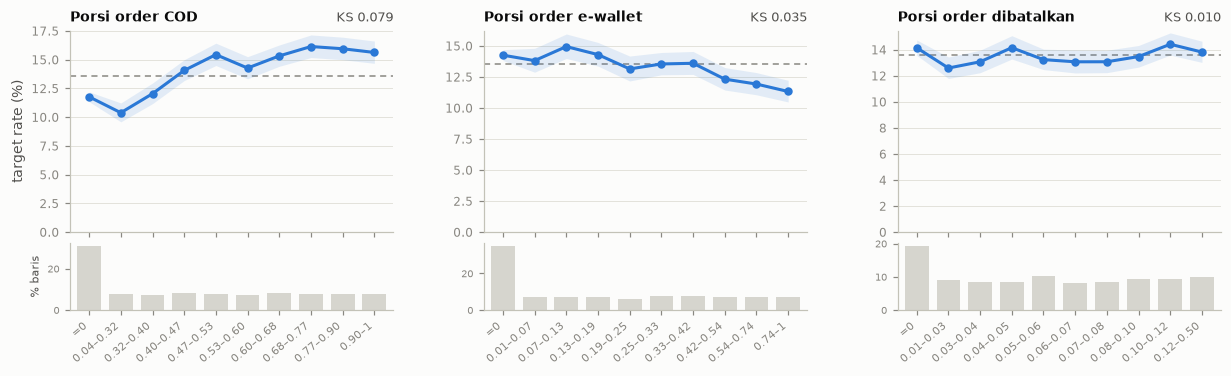

In [10]:
E.plot_rates(df, ["ec_pay_share_COD", "ec_pay_share_e_wallet", "ec_cancel_share_all"], ncols=3,
             titles={"ec_pay_share_COD": "Porsi order COD", "ec_pay_share_e_wallet": "Porsi order e-wallet",
                     "ec_cancel_share_all": "Porsi order dibatalkan"})

**Jawaban Q6.**
- **Porsi COD** sinyal sedang (KS ~0,07): calon gagal bayar sedikit lebih sering COD (~45% vs ~40% order), dan konsisten di semua bulan. Metode bayar lain lemah; kartu kredit ≈ noise.
- **Pembatalan order tidak informatif** (KS ~0,01). Hipotesis "sering membatalkan = tidak punya uang" tidak terbukti di data ini.
- Catatan: fitur yang dihitung pada jendela pendek (mis. COD 90 hari) bisa tampak kuat **hanya karena null-nya** (tidak ada order = null), sehingga sebenarnya mengulang sinyal keterbaruan dari Q2. Bacalah KS fitur ber-null tinggi dengan hati-hati.

## Q7 · Apakah sinyal e-commerce BARU?

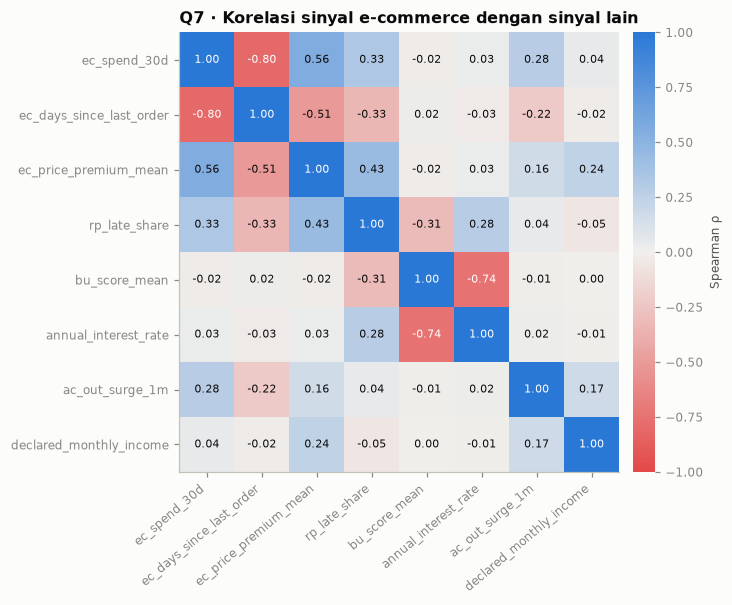

C:\Users\TUF\AppData\Local\Temp\ipykernel_28616\3936638004.py:15: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  d7 = df.filter(pl.col("ec_n_orders_all") > 0).with_columns(expected=pl.col("target").mean().over(pl.col("bu_score_mean").fill_null(0).qcut(10, allow_duplicates=True),
C:\Users\TUF\AppData\Local\Temp\ipykernel_28616\3936638004.py:16: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  pl.col("rp_late_share").fill_null(-1).qcut(5, allow_duplicates=True)))


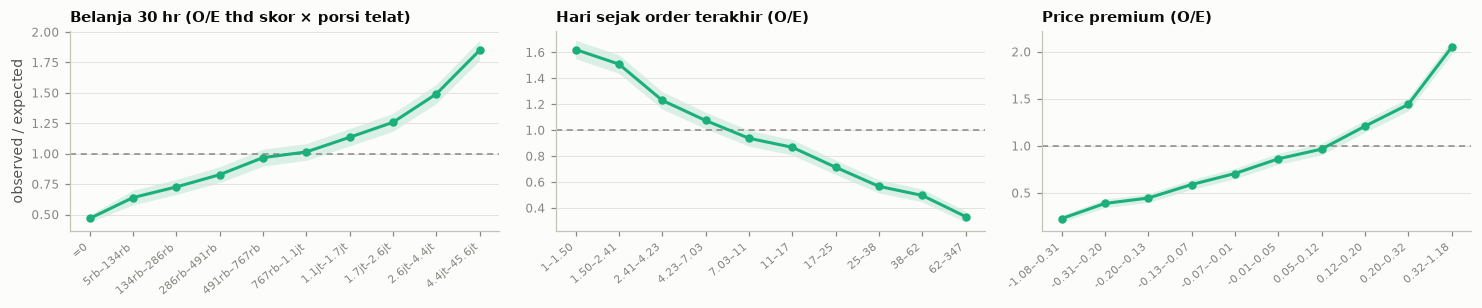

segment,n,ec_price_premium_mean,ec_days_since_last_order,ec_spend_30d,bu_score_mean,annual_interest_rate,rp_late_share
str,i64,f64,f64,f64,f64,f64,f64
"""A. tanpa riwayat""",21000,0.3874,0.3115,0.3327,0.2428,0.1927,0.0
"""B. ada pengajuan, belum ada cicilan""",2688,0.4212,0.2968,0.3228,0.2571,0.178,0.0
"""C. ada riwayat cicilan""",46312,0.3571,0.2699,0.2769,0.2578,0.2446,0.4391


In [11]:
KEYS = ["ec_spend_30d", "ec_days_since_last_order", "ec_price_premium_mean", "rp_late_share", "bu_score_mean",
        "annual_interest_rate", "ac_out_surge_1m", "declared_monthly_income"]
corr = df.select(KEYS).to_pandas().corr(method="spearman").round(2)
fig, ax = plt.subplots(figsize=(7.5, 5.6))
diverge = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
im = ax.imshow(corr.values, cmap=diverge, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(KEYS))); ax.set_xticklabels(KEYS, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(KEYS))); ax.set_yticklabels(KEYS, fontsize=8)
for i in range(len(KEYS)):
    for j in range(len(KEYS)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(corr.values[i, j]) > 0.6 else E.INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Spearman ρ", fontsize=8); cb.outline.set_visible(False)
ax.set_title("Q7 · Korelasi sinyal e-commerce dengan sinyal lain"); plt.tight_layout(); plt.show()

d7 = df.filter(pl.col("ec_n_orders_all") > 0).with_columns(expected=pl.col("target").mean().over(pl.col("bu_score_mean").fill_null(0).qcut(10, allow_duplicates=True),
                                                           pl.col("rp_late_share").fill_null(-1).qcut(5, allow_duplicates=True)))
E.plot_oe(d7, ["ec_spend_30d", "ec_days_since_last_order", "ec_price_premium_mean"], expected="expected", ncols=3,
          titles={"ec_spend_30d": "Belanja 30 hr (O/E thd skor × porsi telat)", "ec_days_since_last_order": "Hari sejak order terakhir (O/E)",
                  "ec_price_premium_mean": "Price premium (O/E)"})
seg_rows = []
for (sg,), g in sorted(df.group_by("segment"), key=lambda t: t[0][0]):
    yy = g["target"].to_numpy()
    seg_rows.append({"segment": sg, "n": g.height, **{c: round(E.ks_stat(yy, g[c].to_numpy()), 4) for c in
                     ["ec_price_premium_mean", "ec_days_since_last_order", "ec_spend_30d", "bu_score_mean", "annual_interest_rate", "rp_late_share"]}})
pl.DataFrame(seg_rows)

**Jawaban Q7 — sinyal e-commerce sebagian besar BARU.**
- Terhadap **skor biro dan suku bunga**, korelasinya ≈ 0, dan terhadap pendapatan juga ≈ 0 (kecuali price premium, ~0,22: orang berpendapatan lebih tinggi sedikit cenderung membeli barang lebih mahal). E-commerce mengukur hal yang sama sekali berbeda dari penilaian kredit tradisional.
- Terhadap **porsi cicilan telat**, ada korelasi sedang (belanja 30 hari ~0,29; price premium ~0,39). Jadi untuk nasabah lama, sebagian informasinya tumpang tindih dengan riwayat bayar. Terhadap lonjakan pengeluaran rekening, korelasinya ~0,24 (sebagian lonjakan rekening memang belanja online).
- Setelah skor biro × porsi telat diperhitungkan, O/E masih bergerak sangat lebar: belanja 30 hari ~0,6 → ~1,7, keterbaruan ~1,7 → ~0,45, dan **price premium ~0,3 → ~2,0**.
- **Per segmen**: di segmen A, price premium dan keterbaruan belanja **lebih kuat daripada skor biro maupun suku bunga**.

## Q8 · Stabilitas sinyal

In [12]:
rows = []
for (q,), g in sorted(df.group_by(pl.col("decision_datetime").dt.quarter().alias("kuartal")), key=lambda t: t[0][0]):
    yy = g["target"].to_numpy()
    rows.append({"kuartal": f"Q{q}", "n": g.height, **{c: round(E.ks_stat(yy, g[c].to_numpy()), 4) for c in
                 ["ec_price_premium_mean", "ec_days_since_last_order", "ec_spend_30d", "ec_order_surge_30d", "bu_score_mean"]}})
display(pl.DataFrame(rows))
from scipy.stats import ks_2samp
fe_te = F.ecommerce_features(ec, te.select("customer_id", pl.col("decision_datetime").alias("cutoff")), cat_medians=CAT_MED)
drift = [dict(feature=c, ks_train_vs_test=round(ks_2samp(fe[c].drop_nulls().to_numpy(), fe_te[c].drop_nulls().to_numpy()).statistic, 4),
              p_value=round(ks_2samp(fe[c].drop_nulls().to_numpy(), fe_te[c].drop_nulls().to_numpy()).pvalue, 3))
         for c in ["ec_price_premium_mean", "ec_days_since_last_order", "ec_spend_30d", "ec_n_30d", "ec_order_surge_30d",
                   "ec_aov_all", "ec_n_orders_all", "ec_pay_share_COD"]]
pl.DataFrame(drift)

kuartal,n,ec_price_premium_mean,ec_days_since_last_order,ec_spend_30d,ec_order_surge_30d,bu_score_mean
str,i64,f64,f64,f64,f64,f64
"""Q1""",17485,0.3476,0.2902,0.2996,0.3137,0.2462
"""Q2""",17550,0.381,0.292,0.3066,0.3151,0.2523
"""Q3""",17378,0.3608,0.2609,0.2788,0.2884,0.2667
"""Q4""",17587,0.3813,0.2904,0.2902,0.3014,0.256


feature,ks_train_vs_test,p_value
str,f64,f64
"""ec_price_premium_mean""",0.0036,0.952
"""ec_days_since_last_order""",0.003,0.992
"""ec_spend_30d""",0.0039,0.913
"""ec_n_30d""",0.0027,0.998
"""ec_order_surge_30d""",0.0038,0.928
"""ec_aov_all""",0.0049,0.692
"""ec_n_orders_all""",0.0063,0.376
"""ec_pay_share_COD""",0.003,0.99


**Jawaban Q8 — stabil.**
- KS sinyal e-commerce utama konsisten di keempat kuartal 2025 (tidak ada tren menurun/naik).
- Distribusi train vs test praktis identik (KS dua-sampel < 0,01, p-value besar).
- **Sampling**: price premium, porsi metode bayar, dan rasio lonjakan tidak bergantung pada skala, sehingga seharusnya hampir sama dengan file penuh. Fitur hitungan & rupiah akan berskala ~2× dan jeda antar order lebih pendek. Pola & rankingnya seharusnya sama, mungkin malah lebih tajam (lebih sedikit noise).

## Q9 · Kontribusi e-commerce terhadap KS

config,n_features,ks_oof,auc_oof,ks_seg_A,ks_seg_B,ks_seg_C
str,i64,f64,f64,f64,f64,f64
"""1. internal + biro + lonjakan rekening (Bagian 4)""",97,0.4248,0.7896,0.2459,0.3473,0.5024
"""2. patokan + e-commerce saja""",61,0.4407,0.7962,0.4637,0.4702,0.4326
"""3. (1) + e-commerce tanpa price premium""",142,0.5062,0.8329,0.4706,0.4763,0.5225
"""4. (1) + e-commerce lengkap""",146,0.5183,0.84,0.487,0.5164,0.5297


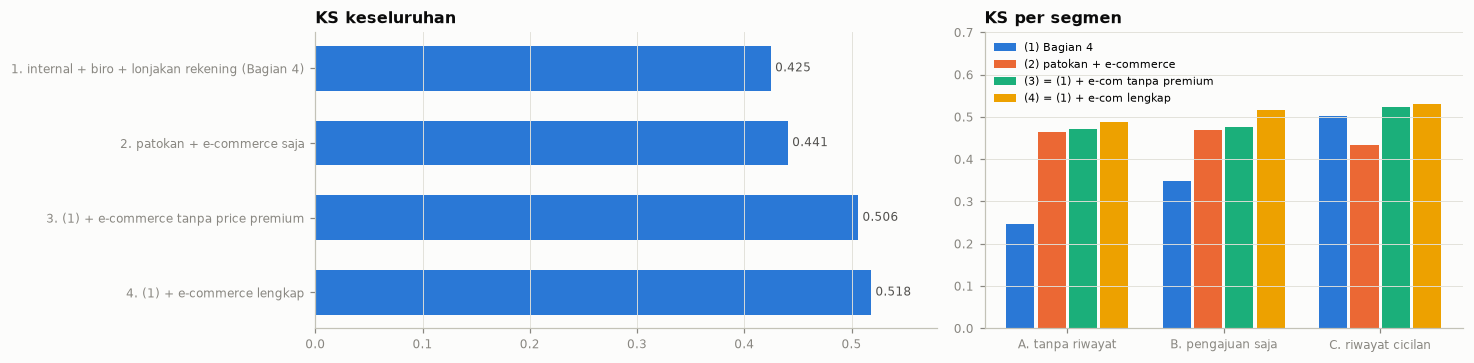

In [13]:
CATS = ["loan_purpose", "region", "employment_type", "housing_status", "segment"]
BASE = ["annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose", "age", "region",
        "employment_type", "employment_tenure_months", "declared_monthly_income", "dependents", "housing_status", "dti"]
INTERNAL = [c for c in df.columns if c.startswith(("pa_", "ln_", "rp_")) and c != "pa_last_decision"] + ["total_dti", "segment"]
BU = [c for c in df.columns if c.startswith("bu_")]
SURGE5 = ["ac_out_surge_1m_med", "ac_out_surge_3m", "ac_out_surge_1m", "ac_excess_out_1m_vs_income", "ac_out_in_ratio_1m"]
EC_NO_PREM = [c for c in EC if "premium" not in c]
configs = {
    "1. internal + biro + lonjakan rekening (Bagian 4)": BASE + INTERNAL + BU + SURGE5,
    "2. patokan + e-commerce saja": BASE + EC,
    "3. (1) + e-commerce tanpa price premium": BASE + INTERNAL + BU + SURGE5 + EC_NO_PREM,
    "4. (1) + e-commerce lengkap": BASE + INTERNAL + BU + SURGE5 + EC,
}
res, imps = [], {}
for name, feats in configs.items():
    oof, ks, auc, imp = E.cv_lgb(df, feats, cat_features=[c for c in CATS if c in feats])
    scored = df.select("segment", "target").with_columns(oof=pl.Series(oof))
    seg = {k[0][:1]: round(E.ks_stat(g["target"].to_numpy(), g["oof"].to_numpy()), 4) for k, g in scored.group_by("segment")}
    res.append(dict(config=name, n_features=len(feats), ks_oof=round(ks, 4), auc_oof=round(auc, 4),
                    ks_seg_A=seg["A"], ks_seg_B=seg["B"], ks_seg_C=seg["C"]))
    imps[name] = imp
res = pl.DataFrame(res)
display(res)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.barh(res["config"].to_list()[::-1], res["ks_oof"].to_list()[::-1], color=E.C_RATE, height=0.6)
for i, v in enumerate(res["ks_oof"].to_list()[::-1]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=E.INK2)
ax.set_xlim(0, 0.58); ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_title("KS keseluruhan")
ax = axes[1]
segs = ["ks_seg_A", "ks_seg_B", "ks_seg_C"]; xs = np.arange(3); wbar = 0.2
for j, row in enumerate(res.iter_rows(named=True)):
    short = ["(1) Bagian 4", "(2) patokan + e-commerce", "(3) = (1) + e-com tanpa premium", "(4) = (1) + e-com lengkap"][j]
    ax.bar(xs + (j - 1.5) * wbar, [row[s] for s in segs], width=wbar - 0.02, color=E.SERIES[j], label=short)
ax.set_xticks(xs); ax.set_xticklabels(["A. tanpa riwayat", "B. pengajuan saja", "C. riwayat cicilan"])
ax.set_ylim(0, 0.7); ax.set_title("KS per segmen"); ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

In [14]:
imps["4. (1) + e-commerce lengkap"].head(20).with_columns(pl.col("gain_pct").round(2))

feature,gain_pct
str,f64
"""ec_price_premium_mean""",18.77
"""rp_late_share""",14.2
"""bu_all_score_mean""",5.46
"""rp_mean_dpd""",5.24
"""ec_price_premium_median""",2.43
"""bu_score_mean""",2.3
"""ln_remaining_amount""",2.05
"""ec_price_premium_30d""",1.92
"""dti""",1.76


**Jawaban Q9 — e-commerce adalah sumber dengan kenaikan KS terbesar setelah repayment.**
- **E-commerce saja + patokan** (tanpa riwayat internal & biro) sudah memberi KS ~0,42, setara gabungan riwayat internal + biro dari Bagian 3.
- Di atas model Bagian 4 (~0,424):
  - e-commerce **tanpa** price premium → ~0,49
  - e-commerce **lengkap** → **~0,51**
- **Segmen A melonjak dari ~0,25 ke ~0,48**, sehingga gap besar antar segmen hampir tertutup. Segmen B ~0,48, segmen C ~0,53.
- Importance: `rp_late_share` tetap teratas, disusul **`ec_price_premium_mean`** di posisi kedua, lalu skor biro dan fitur keterbaruan belanja.

## Ringkasan Bagian 5

| Temuan | Implikasi untuk feature engineering |
|---|---|
| E-commerce tersedia untuk ~100% nasabah, termasuk segmen A | Fondasi sinyal untuk nasabah tanpa riwayat |
| Belanja & order **14–30 hari terakhir** + hari sejak order terakhir (KS ~0,25–0,26) | Jendela 7/14/30/60/90 hari + `days_since_last_order` |
| **Lonjakan belanja menjelang pengajuan** (~2,3×), padahal setahun sebelumnya justru lebih jarang belanja | Rasio 30 hari ÷ baseline (hari 90–365) + level baseline |
| **Price premium** (~25% lebih mahal per unit, semua kategori): KS ~0,34, stabil sejak masa normal | Fitur inti: rata-rata/median log(harga per unit ÷ median kategori), versi 30 hari & baseline |
| Porsi kategori hanya bermakna lewat price premium | Kategori opsional; price premium lebih bersih |
| COD sinyal sedang; pembatalan & kartu kredit ≈ noise | `ec_pay_share_COD`; lewati fitur pembatalan |
| Hampir ortogonal dengan skor biro/bunga/pendapatan; tumpang tindih sedang dengan porsi telat | Benar-benar menambah informasi; paling berharga untuk segmen A & B |
| Stabil antar kuartal, train ≈ test | Aman dipakai |
| KS: ~0,424 → **~0,51**; segmen A ~0,25 → **~0,48** | Bagian 6: sintesis & daftar prioritas fitur |